# 10 · Q3 in the simulator: a read-then-inject controller moves the colony's eps, with limits

**What this notebook shows.** Notebooks 08 and 09 set eps on recorded windows. Here model B *is* the ant, inside the simulator, choosing every move for all 100 ants from its own last 128 steps. At each step a controller:
1. reads the eps B currently believes for this ant (from its own output),
2. injects strength × (eps vector at the target - eps vector at the believed value) at layer 2,
3. samples the move from the injected output.

The target can depend on the ant's state. We compare against the real rule run at the target eps, and measure the **realized eps** from the moves ants actually make: (1 - share of clear steps that follow the rule) / 0.75.

**Results (recorded run, 2 seeds × 1500 steps).**

| target | real rule | model + controller | food: rule / model |
|---|---|---|---|
| eps 0.1 | 0.101 | 0.178 | 333.5 / 245.0 |
| eps 0.5 | 0.501 | 0.541 | 270.5 / 205.5 |
| eps 0.9 | 0.903 | 0.887 | 8.0 / 12.0 |
| 0.6 searching / 0.1 carrying | 0.599 / 0.102 | 0.690 / 0.177 | 277.0 / 114.5 |

With no injection, model B acting alone drifts to about 0.605.

**Conclusion.** The controller moves realized eps where it is told, including a different eps for searching and carrying ants, with no retraining. But it cannot get below about 0.18 and it overshoots the searching target, and colonies run by the model deliver less food than with the real rule. The knob works in closed loop, but with a floor and an efficiency cost. Only 2 seeds, so food differences are indicative.

In [1]:
# Shared plumbing (paths, rule, models, plotting) lives in ant_common.py next to this notebook.
from ant_common import *

setup_plots()
seed_everything(0)
print("device:", DEVICE, "| quick mode:", QUICK)
print("data:  ", DATA_DIR)
print("output:", OUT_DIR)

device: cuda | quick mode: False
data:   /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/dataset_20261025_104552_105991
output: /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models_v2


## 1. Load model B, the eps vectors, and the strength chosen in notebook 08

In [2]:
import json

brain, model_B = load_brain(), load_seq_model("B")
settings = json.loads((OUT_DIR / "q3_injection_settings.json").read_text())
STAGE, ALPHA = settings["stage"], settings["alpha"]
val_goals = {float(k): v for k, v in settings["val_goals"].items()}
M_STAGE = np.load(OUT_DIR / "q2_eps_vectors.npz")["means"][STAGE]           # (10, 64)

# map between true eps and B's own reading scale (B reads 0.1 as about 0.17, see notebook 06)
BASE_EPS = np.array(sorted(val_goals))
BASE_READ = np.maximum.accumulate(np.array([val_goals[e] for e in BASE_EPS]))   # keep it increasing
print(f"injection at {STAGES[STAGE]}, strength {ALPHA}")


def mean_at(eps_values):
    """eps vector at any eps, linearly interpolated between the 10 measured ones. (N,) -> (N, 64)"""
    e = np.clip(eps_values, EPS_GRID[0], EPS_GRID[-1])
    return np.stack([np.interp(e, EPS_GRID, M_STAGE[:, j]) for j in range(M_STAGE.shape[1])], axis=1)


def believed_eps(probs, states, min_clear=5):
    """Per ant: eps B believes, from its own output over the window, mapped back to the true scale."""
    e, clear = implied_eps_steps(probs, states)
    n = clear.sum(1)
    reading = np.where(n >= min_clear, (e * clear).sum(1) / np.maximum(n, 1), np.interp(0.5, BASE_EPS, BASE_READ))
    return np.interp(reading, BASE_READ, BASE_EPS)

injection at after layer 2, strength 3.0


## 2. Policies: the real rule, and model B + controller

In [3]:
class RulePolicy:
    """The real rule, with eps chosen per ant by target_fn(raw obs)."""
    def __init__(self, target_fn):
        self.target_fn = target_fn

    def reset(self, n):
        pass

    def act_probs(self, obs):
        target = self.target_fn(obs)
        return true_probs(obs, target), target

    def observe(self, act):
        pass


class ModelPolicy:
    """Model B acts as the ant, reading its own last SEQ_LEN steps.
    With target_fn: read believed eps, then add alpha * (vec[target] - vec[believed]) at layer STAGE."""
    def __init__(self, model, target_fn=None, alpha=1.0):
        self.model, self.target_fn, self.alpha = model, target_fn, alpha

    def reset(self, n):
        self.buf = np.zeros((n, SEQ_LEN, 27), dtype=np.float32)    # rolling window of tokens per ant
        self.len = 0
        self.prev = np.zeros((n, 4), dtype=np.float32)

    def act_probs(self, obs):
        s = normalize(obs)
        token = np.concatenate([s, brain_probs(brain, s), self.prev], axis=1)    # (N, 27), same as training
        if self.len < SEQ_LEN:
            self.buf[:, self.len] = token
            self.len += 1
        else:
            self.buf = np.roll(self.buf, -1, axis=1)
            self.buf[:, -1] = token
        x = torch.from_numpy(self.buf[:, :self.len]).to(DEVICE)
        p0 = run_with_injection(self.model, x)                                   # no injection
        if self.target_fn is None:
            return p0[:, -1], np.full(len(obs), np.nan)
        target = self.target_fn(obs)
        vec = self.alpha * (mean_at(target) - mean_at(believed_eps(p0, self.buf[:, :self.len, :19])))
        return run_with_injection(self.model, x, STAGE, vec)[:, -1], target

    def observe(self, act):
        self.prev = np.eye(4, dtype=np.float32)[act]

## 3. Colony loop and the realized-eps measure

All ants sense, then one batched decision for all ants, then all act. This order differs slightly from the simulator's one-ant-at-a-time loop, so the real rule is also run through this same loop as the reference.

In [4]:
sim_mod, Simulation, Config = import_sim()


def obs_from(ant, local):
    return np.concatenate([[float(local.on_food), float(local.at_home), float(ant.carrying)],
                           local.see_food, local.see_home, local.smell_food, local.smell_home]).astype(np.float32)


def run_colony(policy, seed, T):
    sim = Simulation(Config(seed=seed))                  # Config's epsilon is unused: the policy decides
    for x, y in FOOD_PATCHES:
        sim.world.add_food(x, y, radius=4, amount_per_cell=5)
    rng = np.random.default_rng(seed + 1000)
    policy.reset(len(sim.ants))
    log_obs, log_act = [], []
    for t in range(T):
        locals_ = [sim_mod.sense(a, sim.world) for a in sim.ants]
        obs = np.stack([obs_from(a, l) for a, l in zip(sim.ants, locals_)])          # (N, 19) raw
        probs, _ = policy.act_probs(obs)
        act = np.minimum((rng.random((len(obs), 1)) > probs.cumsum(1)).sum(1), N_ACTIONS - 1)
        policy.observe(act)
        for ant, local, d in zip(sim.ants, locals_, act):
            was_carrying = ant.carrying
            if local.on_food and not ant.carrying:
                sim_mod.pick_food(ant, sim.world)
            elif local.at_home and ant.carrying:
                sim_mod.drop_food(ant, sim.world)
            step = np.zeros(N_ACTIONS)
            step[d] = 1.0
            sim_mod.move(ant, step, sim.world)
            sim_mod.drop_pheromone(ant, sim.world)
            if ant.carrying == was_carrying:
                ant.steps_since_event += 1
        sim.world.update()
        sim.t += 1
        log_obs.append(obs)
        log_act.append(act)
    return dict(obs=np.stack(log_obs), act=np.stack(log_act), delivered=sim.world.food_delivered)


def realized(log, warmup):
    """Measured randomness from the moves ants actually made: (1 - follow rate) / 0.75 on clear steps."""
    obs, act = log["obs"][warmup:].reshape(-1, 19), log["act"][warmup:].reshape(-1)
    clear, follow, carrying = n_ties(obs) == 1, act == best_dir(obs), obs[:, CARRYING] > 0.5
    return {name: (1 - follow[m].mean()) / 0.75 if m.any() else np.nan
            for name, m in [("all", clear), ("searching", clear & ~carrying), ("carrying", clear & carrying)]}

## 4. Run the closed-loop experiments

In [5]:
T_STEPS = 150 if QUICK else 1500
WARMUP = 20 if QUICK else 200
SEEDS = [0] if QUICK else [0, 1]
CONDITIONS = {
    "eps 0.1": lambda o: np.full(len(o), 0.1),
    "eps 0.5": lambda o: np.full(len(o), 0.5),
    "eps 0.9": lambda o: np.full(len(o), 0.9),
    "0.6 searching / 0.1 carrying": lambda o: np.where(o[:, CARRYING] > 0.5, 0.1, 0.6),
}

rows = []
for seed in SEEDS:
    t0 = time.time()
    log = run_colony(ModelPolicy(model_B), seed, T_STEPS)
    rows.append(dict(condition="no target", policy="model, no injection", seed=seed,
                     delivered=log["delivered"], **realized(log, WARMUP)))
    for name, fn in CONDITIONS.items():
        for policy_name, policy in [("real rule", RulePolicy(fn)),
                                    ("model + controller", ModelPolicy(model_B, fn, alpha=ALPHA))]:
            log = run_colony(policy, seed, T_STEPS)
            rows.append(dict(condition=name, policy=policy_name, seed=seed,
                             delivered=log["delivered"], **realized(log, WARMUP)))
    print(f"seed {seed} done in {time.time() - t0:.0f} s")

closed = pd.DataFrame(rows)
closed.to_csv(OUT_DIR / "q3_closed_loop.csv", index=False)
summary = closed.groupby(["condition", "policy"])[["all", "searching", "carrying", "delivered"]].mean()
print(summary.round(3))

seed 0 done in 166 s
seed 1 done in 96 s
                                                    all  searching  carrying  \
condition                    policy                                            
0.6 searching / 0.1 carrying model + controller   0.596      0.699     0.250   
                             real rule            0.472      0.599     0.102   
eps 0.1                      model + controller   0.174      0.181     0.167   
                             real rule            0.101      0.100     0.103   
eps 0.5                      model + controller   0.562      0.541     0.583   
                             real rule            0.501      0.499     0.502   
eps 0.9                      model + controller   0.888      0.896     0.869   
                             real rule            0.903      0.902     0.907   
no target                    model, no injection  0.581      0.583     0.579   

                                                  delivered  
condition       

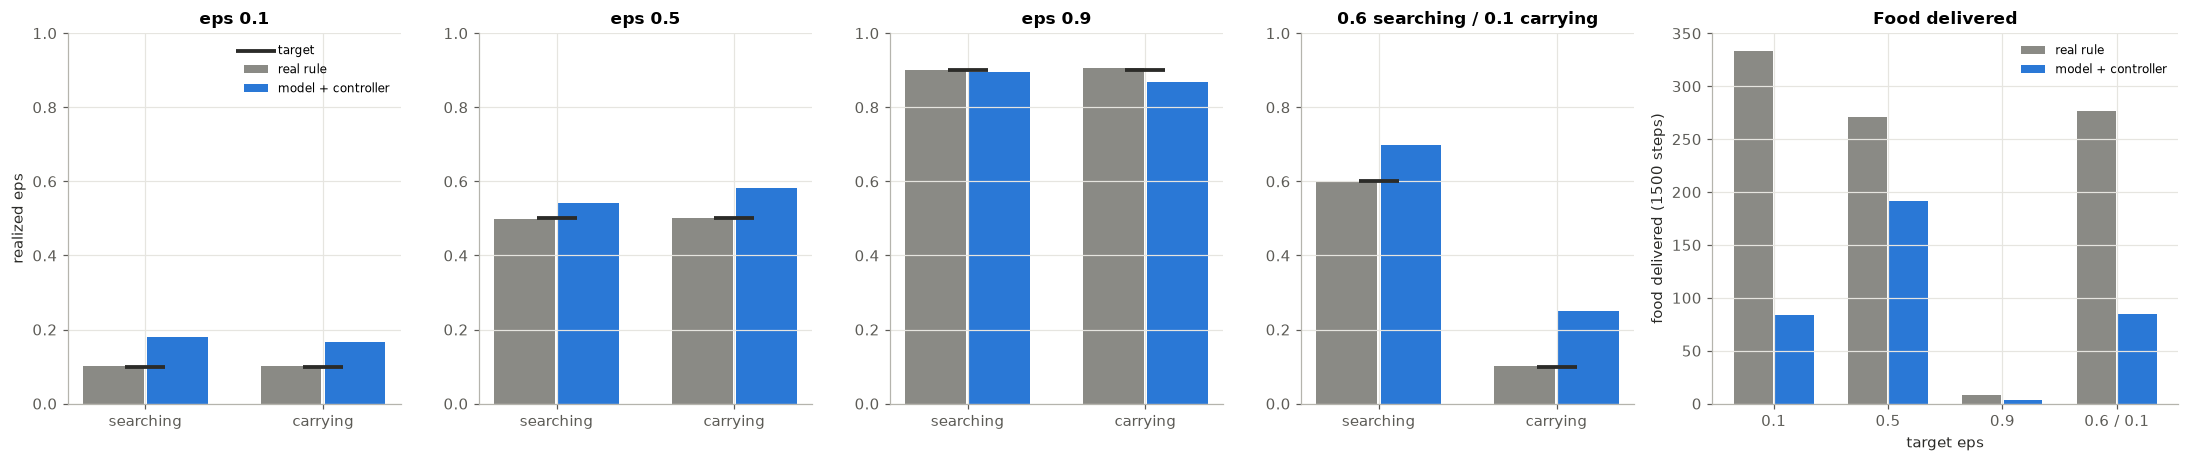

In [6]:
targets = {"eps 0.1": (0.1, 0.1), "eps 0.5": (0.5, 0.5), "eps 0.9": (0.9, 0.9),
           "0.6 searching / 0.1 carrying": (0.6, 0.1)}                       # (searching, carrying)
policy_colors = {"real rule": C["gray"], "model + controller": C["blue"]}

fig, axes = plt.subplots(1, len(targets) + 1, figsize=(20, 4.3),
                         gridspec_kw=dict(width_ratios=[1] * len(targets) + [1.4]))
for ax, (name, (t_search, t_carry)) in zip(axes, targets.items()):
    part = summary.loc[name]
    xs = np.arange(2)
    for i, policy in enumerate(["real rule", "model + controller"]):
        ax.bar(xs + (i - 0.5) * 0.36, part.loc[policy, ["searching", "carrying"]], width=0.34,
               color=policy_colors[policy], label=policy)
    ax.scatter(xs, [t_search, t_carry], color=C["ink"], marker="_", s=700, lw=2.5, zorder=3, label="target")
    ax.set_xticks(xs, ["searching", "carrying"])
    ax.set(ylim=(0, 1), title=name)
axes[0].set_ylabel("realized eps")
axes[0].legend(fontsize=8)

ax = axes[-1]
names = list(targets)
xs = np.arange(len(names))
for i, policy in enumerate(["real rule", "model + controller"]):
    ax.bar(xs + (i - 0.5) * 0.36, [summary.loc[(n, policy), "delivered"] for n in names], width=0.34,
           color=policy_colors[policy], label=policy)
ax.set_xticks(xs, ["0.1", "0.5", "0.9", "0.6 / 0.1"])
ax.set(xlabel="target eps", ylabel=f"food delivered ({T_STEPS} steps)", title="Food delivered")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Analysis.** Recorded (mean of 2 seeds; realized eps searching / carrying):

| condition | real rule | model + controller | food: rule / model |
|---|---|---|---|
| eps 0.1 | 0.100 / 0.103 | 0.185 / 0.161 | 333.5 / 245.0 |
| eps 0.5 | 0.499 / 0.502 | 0.525 / 0.558 | 270.5 / 205.5 |
| eps 0.9 | 0.902 / 0.907 | 0.886 / 0.888 | 8.0 / 12.0 |
| 0.6 / 0.1 | 0.599 / 0.102 | 0.690 / 0.177 | 277.0 / 114.5 |

- **It steers.** Left alone, model B settles near 0.605. With the controller, realized eps follows the target from 0.18 up to 0.89, and searching and carrying ants get clearly different eps (0.69 vs 0.18) in the state-dependent condition.
- **Floor at low eps.** The target 0.1 lands at about 0.18. This matches B's own reading bias (it reads true 0.1 as about 0.17), so the floor probably comes from the model, not the controller.
- **Efficiency cost.** At the same realized eps the model colony delivers less food, most of all in the state-dependent condition (114.5 vs 277.0), where carrying ants are noisier than intended (0.18 vs 0.10) and searching ants more so (0.69 vs 0.60).
- **Caveat.** Model B is the given-the-rule model from notebook 06, and only 2 seeds were run.